# EDA: ASEAN-5 (+ India) index data

Run top to bottom. Expects the CSVs in `Dataset/` next to this notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("Dataset")
OUT_DIR = Path("eda_output")  # saved figures, used by eda_report.md
OUT_DIR.mkdir(exist_ok=True)

FILES = {
    "Indonesia":   "Jakarta Stock Exchange Composite Index Historical Data.csv",
    "Malaysia":    "FTSE Malaysia KLCI Historical Data.csv",
    "Philippines": "FTSE Philippines Historical Data.csv",
    "Singapore":   "FTSE Straits Times Singapore Historical Data.csv",
    "Thailand":    "SET Thailand Index Historical Data.csv",
    "India":       "Nifty 50 Historical Data.csv",  # not ASEAN, kept as a benchmark
}

In [2]:
def load(path):
    df = pd.read_csv(path, encoding="utf-8-sig", thousands=",")
    df = df.rename(columns={"Price": "Close"})
    # Dates come in two styles ("01-03-2012" and "03/15/2023"); both are month-first.
    df["Date"] = pd.to_datetime(df["Date"].str.replace("-", "/"), format="%m/%d/%Y")
    return df.set_index("Date").sort_index()[["Open", "High", "Low", "Close"]]


raw = {name: load(DATA_DIR / file) for name, file in FILES.items()}
raw["Indonesia"].head()

,Open,High,Low,Close
Date,,,,
2012-01-02,3821.63,3825.10,3797.00,3809.14
2012-01-03,3808.69,3858.19,3808.69,3857.88
2012-01-04,3858.06,3921.17,3858.06,3907.42
2012-01-05,3907.51,3924.05,3893.19,3906.26
2012-01-06,3906.44,3906.68,3852.75,3869.41


## 1. What's in the files?

In [3]:
pd.DataFrame({
    name: {
        "rows": len(df),
        "start": df.index.min().date(),
        "end": df.index.max().date(),
        "O=H=L=C rows %": round(100 * (df.nunique(axis=1) == 1).mean(), 1), # df.nunique(axis=1) == 1: count the different values in each row. == 1: is the row flat(are all the same?)
    }
    for name, df in raw.items()
}).T

,rows,start,end,O=H=L=C rows %
Indonesia,2747,2012-01-02,2023-03-16,0.4
Malaysia,2762,2012-01-03,2023-03-16,0.5
Philippines,2922,2012-01-03,2023-03-15,99.4
Singapore,2695,2012-01-03,2023-03-16,0.9
Thailand,2732,2012-01-04,2023-03-16,0.0
India,3277,2010-01-04,2023-03-16,0.0


Raw daily index levels (OHLC). No volume, no adjusted close.  
Philippines is close-only: Open/High/Low are copies of Close.

## 2. Is the data clean?

In [4]:
def quality_report(df):
    close = df["Close"]
    gap_days = df.index.to_series().diff().dt.days #df.index holds the dates and then to_series() turns them into a normal column. diff subtracts previous rows date from each date and dt.days turns difference into a whole num of days
    unchanged = close.diff() == 0 #todays close - yesterdays close and checking if its 0
    longest_frozen = unchanged.groupby((~unchanged).cumsum()).sum().max()
    bad_ohlc = (df["High"] < df[["Open", "Close"]].max(axis=1)) | (
        df["Low"] > df[["Open", "Close"]].min(axis=1)
    )
    return {
        "duplicate dates": df.index.duplicated().sum(),
        "weekend rows": (df.index.dayofweek >= 5).sum(),
        "gaps > 5 days": (gap_days > 5).sum(),
        "longest gap (days)": int(gap_days.max()),
        "unchanged closes": unchanged.sum(),
        "longest frozen run": longest_frozen,
        "bad OHLC rows": bad_ohlc.sum(),
        "High = Low rows": (df["High"] == df["Low"]).sum(),
    }


pd.DataFrame({name: quality_report(df) for name, df in raw.items()}).T

,duplicate dates,weekend rows,gaps > 5 days,longest gap (days),unchanged closes,longest frozen run,bad OHLC rows,High = Low rows
Indonesia,0,10,11,12,14,2,8,12
Malaysia,0,12,3,6,18,1,1,15
Philippines,0,15,0,5,201,4,0,2904
Singapore,0,0,1,202,23,1,0,23
Thailand,0,0,6,6,1,1,0,0
India,0,12,1,6,3,1,0,0


Gaps longer than 10 days. Indonesia's are Eid closures; Singapore's is missing data.

In [5]:
for name, df in raw.items():
    dates = df.index.to_series()
    gap_days = dates.diff().dt.days
    for end in gap_days[gap_days > 10].index:
        start = dates.shift(1)[end]
        print(f"{name:12} {start:%Y-%m-%d} -> {end:%Y-%m-%d}  ({gap_days[end]:.0f} days)")

Indonesia    2017-06-22 -> 2017-07-03  (11 days)
Indonesia    2018-06-08 -> 2018-06-20  (12 days)
Indonesia    2022-04-28 -> 2022-05-09  (11 days)
Singapore    2020-05-19 -> 2020-12-07  (202 days)


Largest daily moves. All real (March 2020) except Singapore's +8.7%, which spans the missing months.

In [6]:
for name, df in raw.items():
    r = np.log(df["Close"]).diff()
    top = r.abs().nlargest(3).index
    print(f"{name:12}", ",  ".join(f"{d:%Y-%m-%d} {r[d]:+.1%}" for d in top))

Indonesia    2020-03-26 +9.7%,  2020-03-09 -6.8%,  2013-08-19 -5.7%
Malaysia     2020-03-20 +6.6%,  2020-03-13 -5.4%,  2020-03-16 -4.9%
Philippines  2020-03-19 -14.5%,  2020-03-12 -10.4%,  2020-03-16 -8.5%
Singapore    2020-12-07 +8.7%,  2020-03-23 -7.6%,  2020-03-09 -6.2%
Thailand     2020-03-12 -11.4%,  2020-03-23 -9.6%,  2020-03-09 -8.3%
India        2020-03-23 -13.9%,  2020-03-12 -8.7%,  2020-04-07 +8.4%


Unchanged closes are holiday/weekend filler rows, e.g. Philippines:

In [7]:
ph = raw["Philippines"]["Close"]
[f"{d:%a %Y-%m-%d}" for d in ph.index[ph.diff() == 0][:8]]

['Mon 2012-01-23',
 'Thu 2012-04-05',
 'Tue 2012-05-01',
 'Tue 2012-06-12',
 'Tue 2012-08-07',
 'Mon 2012-08-20',
 'Tue 2012-08-21',
 'Mon 2012-08-27']

**Cleaning:**
- drop rows whose close equals the previous close (filler rows)
- widen High/Low where they don't contain Open and Close (the 9 bad rows, all off by less than 0.5%)
- drop returns that span a gap of more than 14 days (Singapore 2020)

In [8]:
def clean(df):
    """Drop filler rows and make High/Low consistent with Open/Close."""
    df = df[df["Close"].diff() != 0].copy()  # unchanged close = holiday/weekend filler
    ohlc = df[["Open", "High", "Low", "Close"]]
    df["High"] = ohlc.max(axis=1)  # High can't be below Open or Close
    df["Low"] = ohlc.min(axis=1)   # Low can't be above Open or Close
    return df


def log_returns(df, max_gap_days=14):
    """Daily log returns, minus any return that spans missing data (Singapore 2020)."""
    r = np.log(df["Close"]).diff()
    gap_days = df.index.to_series().diff().dt.days
    return r[gap_days <= max_gap_days]


cleaned = {name: clean(df) for name, df in raw.items()}
prices = pd.DataFrame({name: df["Close"] for name, df in cleaned.items()})
rets = pd.DataFrame({name: log_returns(df) for name, df in cleaned.items()})

Same checks after cleaning:

In [9]:
pd.DataFrame({name: quality_report(df) for name, df in cleaned.items()}).T

,duplicate dates,weekend rows,gaps > 5 days,longest gap (days),unchanged closes,longest frozen run,bad OHLC rows,High = Low rows
Indonesia,0,0,12,12,0,0,0,0
Malaysia,0,0,3,6,0,0,0,0
Philippines,0,0,9,7,0,0,0,2703
Singapore,0,0,1,202,0,0,0,0
Thailand,0,0,6,6,0,0,0,0
India,0,12,1,6,0,0,0,0


**Philippines:** High = Low on every day, because only the close is real. Any indicator that divides by the day's High − Low (e.g. the A/D oscillator) is undefined for this market. Indicators built on n-day highs and lows (Stochastic %K, Williams %R) still compute, but only from closes.

## 3. What do returns look like?

In [10]:
pd.DataFrame({
    "days": rets.count(),
    "mean %": 100 * rets.mean(),
    "std %": 100 * rets.std(),
    "ann. vol %": 100 * rets.std() * np.sqrt(252),
    "skew": rets.skew(),
    "excess kurt": rets.kurt(),
    "min %": 100 * rets.min(),
    "max %": 100 * rets.max(),
    "lag-1 autocorr": rets.apply(lambda s: s.dropna().autocorr()),
}).round(3)

,days,mean %,std %,ann. vol %,skew,excess kurt,min %,max %,lag-1 autocorr
Indonesia,2732,0.020,1.009,16.010,-0.264,7.027,-6.805,9.704,0.047
Malaysia,2743,-0.003,0.671,10.649,-0.181,8.492,-5.405,6.626,0.016
Philippines,2720,0.015,1.242,19.716,-1.098,12.518,-14.471,7.356,0.013
Singapore,2670,0.003,0.802,12.724,-0.583,9.252,-7.637,5.895,-0.022
Thailand,2730,0.015,0.970,15.406,-1.334,18.086,-11.428,7.653,-0.015
India,3273,0.036,1.089,17.292,-0.918,13.319,-13.904,8.400,0.011


Normal data would have skew ≈ 0 and excess kurtosis ≈ 0.

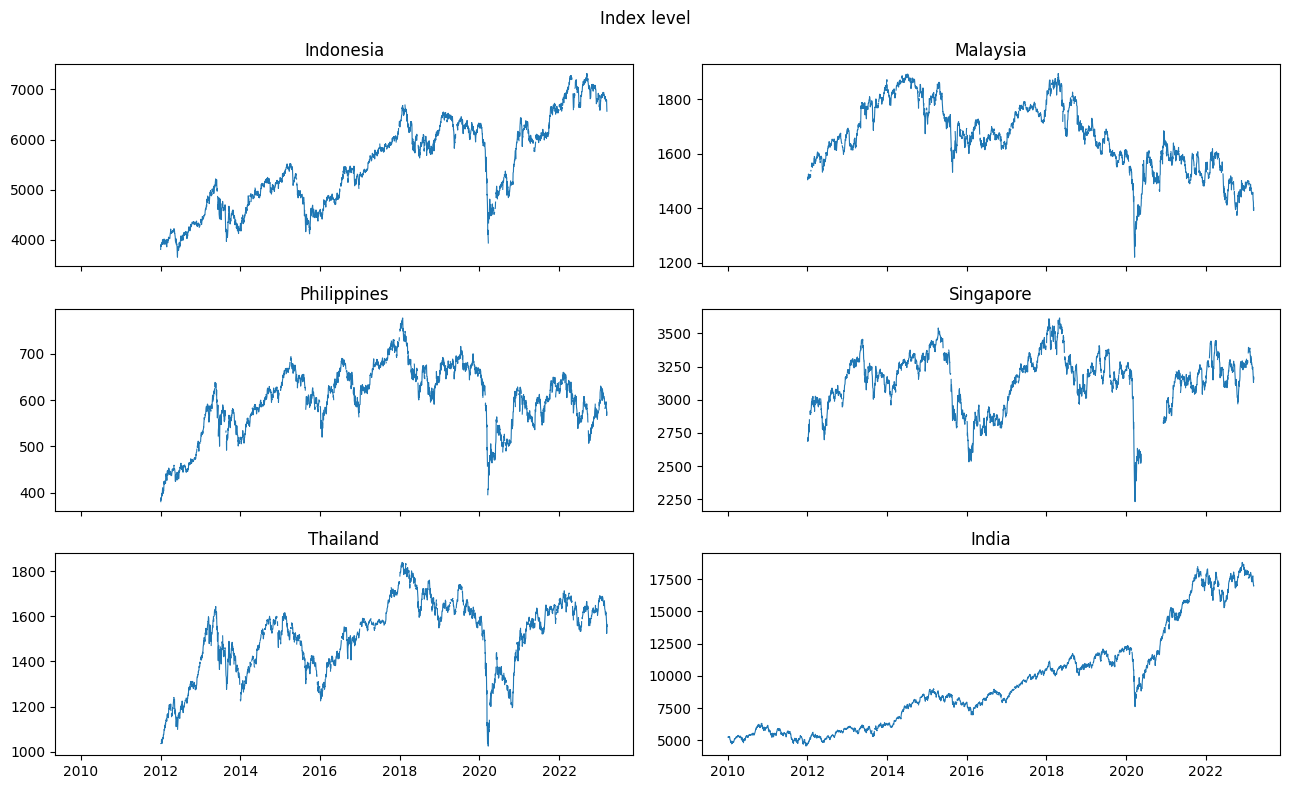

In [11]:
def six_panels(title):
    fig, axes = plt.subplots(3, 2, figsize=(13, 8), sharex=True)
    fig.suptitle(title)
    return fig, axes.flat


fig, axes = six_panels("Index level")
for ax, name in zip(axes, prices):
    ax.plot(prices[name], lw=0.8)
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUT_DIR / "1_prices.png", dpi=120)
plt.show()

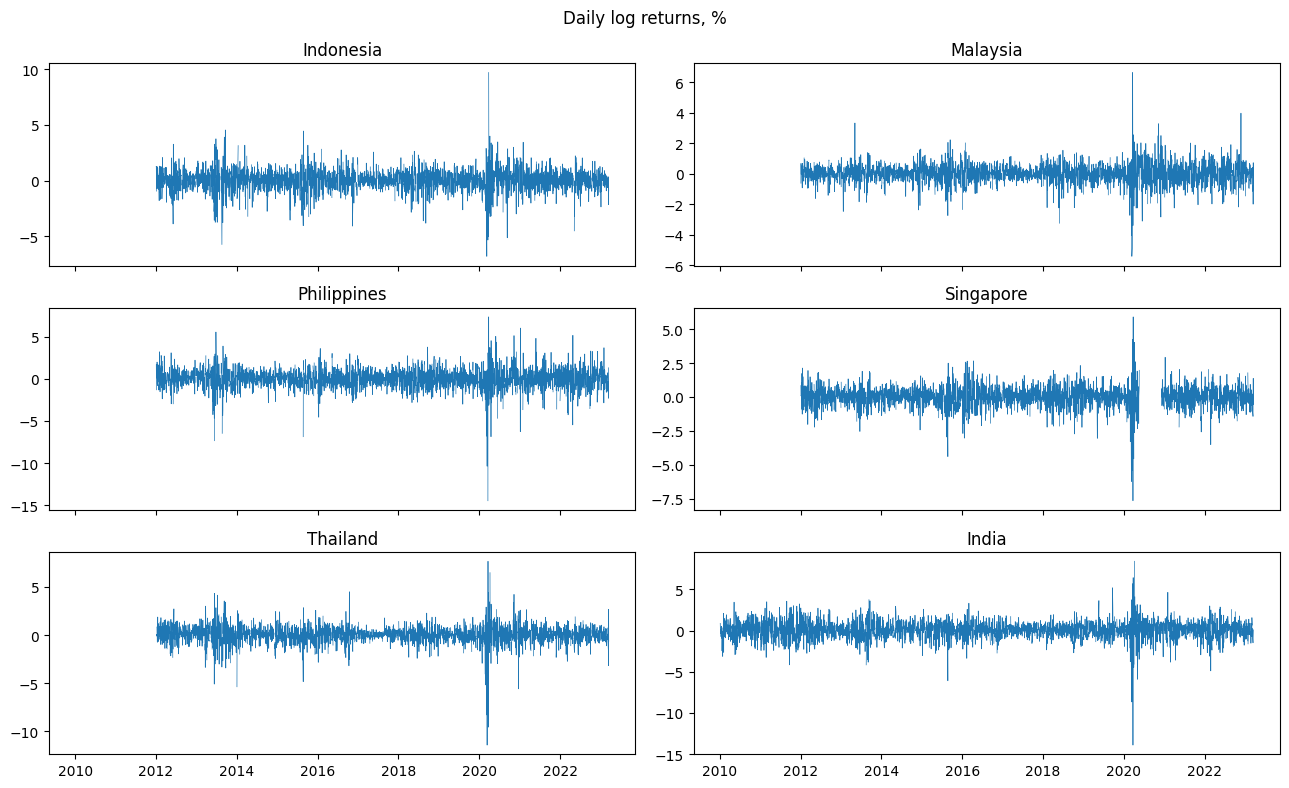

In [12]:
fig, axes = six_panels("Daily log returns, %")
for ax, name in zip(axes, rets):
    ax.plot(100 * rets[name], lw=0.5)
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUT_DIR / "2_returns.png", dpi=120)
plt.show()

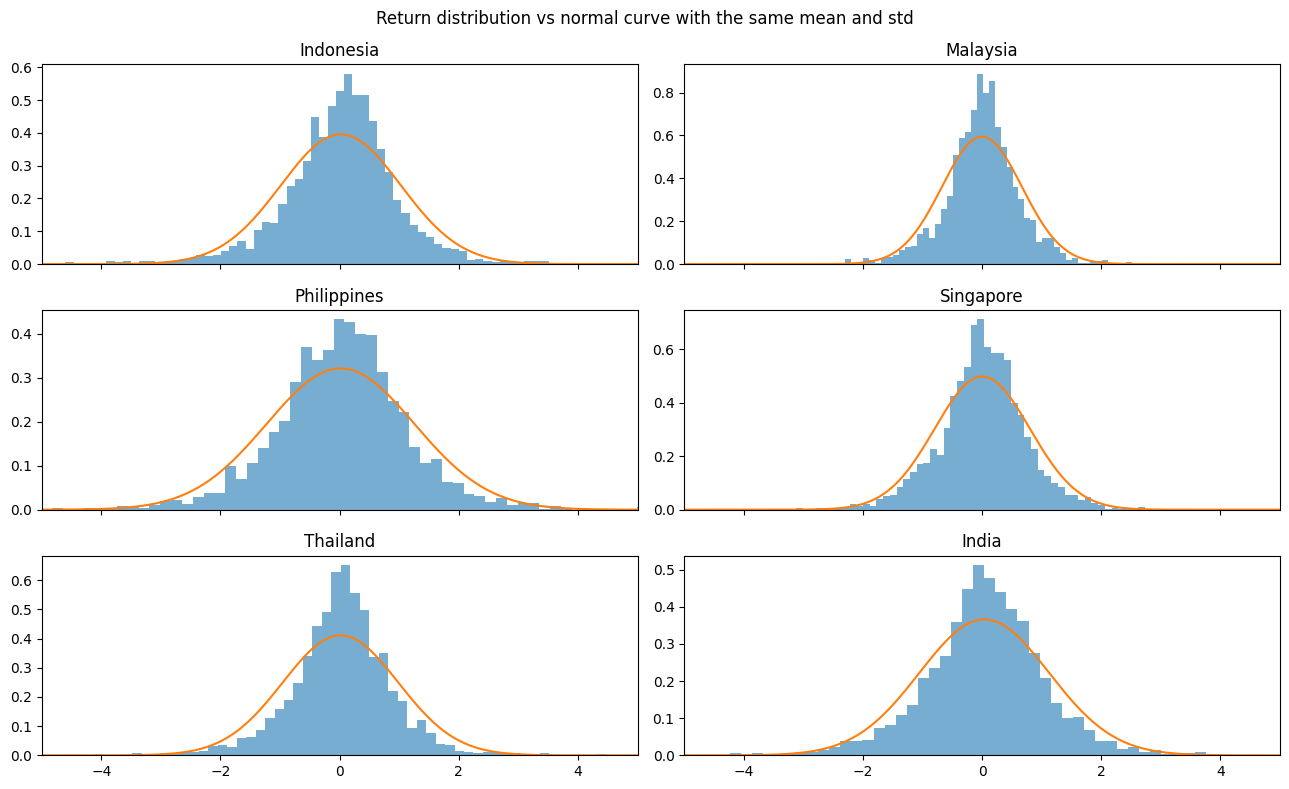

In [13]:
fig, axes = six_panels("Return distribution vs normal curve with the same mean and std")
for ax, name in zip(axes, rets):
    r = 100 * rets[name].dropna()
    ax.hist(r, bins=120, density=True, alpha=0.6)
    x = np.linspace(-5, 5, 200)
    ax.plot(x, np.exp(-0.5 * ((x - r.mean()) / r.std()) ** 2) / (r.std() * np.sqrt(2 * np.pi)))
    ax.set_xlim(-5, 5)
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUT_DIR / "3_return_hist.png", dpi=120)
plt.show()

## 4. Share of up days, %

2023 covers Jan–Mar only.

In [14]:
is_up = rets > 0
has_return = rets.notna()
up_share = 100 * is_up.groupby(rets.index.year).sum() / has_return.groupby(rets.index.year).sum()
up_share.loc["All"] = 100 * is_up.sum() / has_return.sum()
up_share.round(1)

,Indonesia,Malaysia,Philippines,Singapore,Thailand,India
Date,,,,,,
2010,NaN,NaN,NaN,NaN,NaN,54.6
2011,NaN,NaN,NaN,NaN,NaN,43.3
2012,55.5,59.0,56.1,55.2,59.8,56.0
2013,54.5,53.4,57.3,53.8,53.9,50.4
2014,58.7,52.2,56.4,52.0,57.1,58.4
2015,52.5,48.0,53.8,46.4,45.7,48.8
2016,57.3,50.4,50.2,47.2,58.6,52.8
2017,55.9,51.9,55.6,51.2,56.0,56.3
2018,51.2,52.7,46.5,47.8,51.4,54.1


## 5. How good is guessing?

Target: will today close higher than yesterday? Three guesses that use no model:
- **always up** / **always down**: predict the same direction every day
- **same as yesterday**: predict today's direction = yesterday's direction

Every market is tested on the same days: 2021-01-01 to the end of the data.

Three scores:
- **accuracy**: share of days called right. Easy to fool: if 53% of days are down, "always down" scores 53%.
- **balanced accuracy**: average of the hit rate on up days and the hit rate on down days. Any constant guess scores exactly 50%.
- **MCC**: correlation between guesses and outcomes, from −1 to 1. 0 means no skill.

In [15]:
TEST_START = "2021-01-01"  # same test window for every market


def score(actual, predicted):
    """Accuracy, balanced accuracy and MCC for up/down guesses (True = up)."""
    tp = (actual & predicted).sum()    # up days called up
    tn = (~actual & ~predicted).sum()  # down days called down
    fp = (~actual & predicted).sum()   # down days called up
    fn = (actual & ~predicted).sum()   # up days called down
    mcc_denominator = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return {
        "accuracy %": 100 * (tp + tn) / len(actual),
        "balanced acc %": 100 * (tp / (tp + fn) + tn / (tn + fp)) / 2,
        "MCC": (tp * tn - fp * fn) / mcc_denominator if mcc_denominator else 0.0,
    }


results = {}
for name in rets:
    up = rets[name].dropna() > 0
    guesses = {
        "always up": pd.Series(True, index=up.index),
        "always down": pd.Series(False, index=up.index),
        "same as yesterday": up.shift(1, fill_value=False),
    }
    test = up.index >= TEST_START
    results[name] = {
        (guess, metric): value
        for guess, predicted in guesses.items()
        for metric, value in score(up[test], predicted[test]).items()
    }

results = pd.DataFrame(results).T
results.columns.names = ["guess", "score"]
results.round(2)

guess        always up                     always down                      \
score       accuracy % balanced acc %  MCC  accuracy % balanced acc %  MCC   
Indonesia        52.38           50.0  0.0       47.62           50.0  0.0   
Malaysia         47.49           50.0  0.0       52.51           50.0  0.0   
Philippines      51.85           50.0  0.0       48.15           50.0  0.0   
Singapore        53.25           50.0  0.0       46.75           50.0  0.0   
Thailand         51.50           50.0  0.0       48.50           50.0  0.0   
India            51.46           50.0  0.0       48.54           50.0  0.0   

guess       same as yesterday                       
score              accuracy % balanced acc %   MCC  
Indonesia               46.15          46.03 -0.08  
Malaysia                51.58          51.46  0.03  
Philippines             49.45          49.38 -0.01  
Singapore               48.01          47.79 -0.04  
Thailand                51.31          51.27  0.03  
India                   57.85          57.82  0.16

Bar to beat: the best of the three guesses on each score.

In [16]:
results.T.groupby(level="score").max().T[["accuracy %", "balanced acc %", "MCC"]].round(2)

score,accuracy %,balanced acc %,MCC
Indonesia,52.38,50.00,0.00
Malaysia,52.51,51.46,0.03
Philippines,51.85,50.00,0.00
Singapore,53.25,50.00,0.00
Thailand,51.50,51.27,0.03
India,57.85,57.82,0.16
